Iteration   1 | Product X = 42.99 | Product Y = 25.89 | Cost = Rs. 2798.97
Iteration   2 | Product X = 29.21 | Product Y = 15.48 | Cost = Rs. 1796.12
Iteration   3 | Product X = 29.21 | Product Y = 15.48 | Cost = Rs. 1796.12
Iteration   4 | Product X = 29.20 | Product Y = 15.47 | Cost = Rs. 1795.63
Iteration   5 | Product X = 29.19 | Product Y = 15.47 | Cost = Rs. 1795.25
Iteration   6 | Product X = 29.19 | Product Y = 15.47 | Cost = Rs. 1795.25
Iteration   7 | Product X = 29.19 | Product Y = 15.47 | Cost = Rs. 1795.05
Iteration   8 | Product X = 29.18 | Product Y = 15.47 | Cost = Rs. 1794.69
Iteration   9 | Product X = 29.18 | Product Y = 15.47 | Cost = Rs. 1794.69
Iteration  10 | Product X = 29.18 | Product Y = 15.47 | Cost = Rs. 1794.69
Iteration  11 | Product X = 29.16 | Product Y = 15.46 | Cost = Rs. 1793.90
Iteration  12 | Product X = 29.15 | Product Y = 15.46 | Cost = Rs. 1793.21
Iteration  13 | Product X = 29.15 | Product Y = 15.46 | Cost = Rs. 1793.16
Iteration  14 | Product X

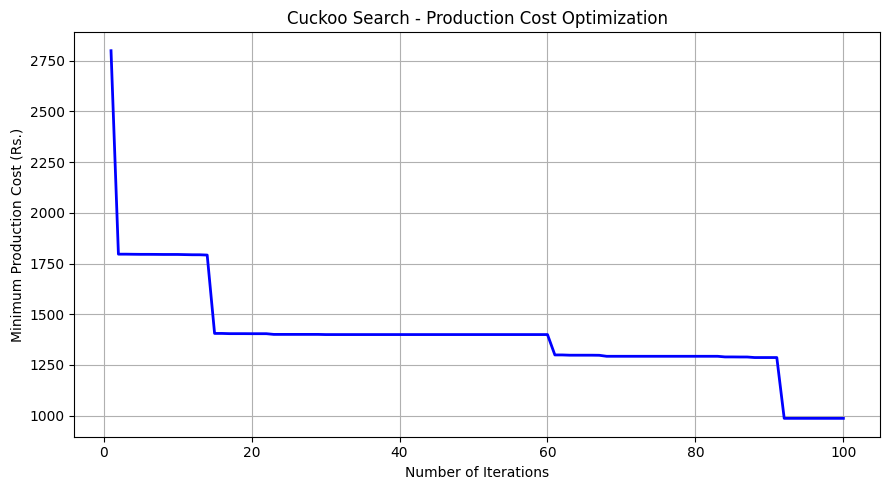

In [ ]:

import numpy as np
import math
import matplotlib.pyplot as plt

# ==========================================
# STEP 1: INITIALIZATION
# ==========================================

n = 3
Pa = 0.25
alpha = 0.01
lam = 1.5
MaxIter = 100

# Production constraints
X_min, X_max = 10, 100
Y_min, Y_max = 5, 80
capacity = 120

# Production costs
cost_X = 35
cost_Y = 50

# ==========================================
# STEP 2: FITNESS FUNCTION
# ==========================================

def fitness(solution):

    x, y = solution

    total_cost = cost_X * x + cost_Y * y

    return total_cost


# ==========================================
# STEP 3: GENERATE FEASIBLE SOLUTION
# ==========================================

def generate_solution():

    x = np.random.uniform(X_min, X_max)
    y = np.random.uniform(Y_min, Y_max)

    if x + y > capacity:
        y = min(y, capacity - x)

    return np.array([x, y])


# ==========================================
# STEP 4: LEVY FLIGHT
# MANTEgna METHOD
# ==========================================

def levy_flight():

    sigma_u = (
        math.gamma(1 + lam) *
        math.sin(math.pi * lam / 2) /
        (
            math.gamma((1 + lam) / 2) *
            lam *
            2 ** ((lam - 1) / 2)
        )
    ) ** (1 / lam)

    u = np.random.normal(0, sigma_u, 2)

    v = np.random.normal(0, 1, 2)

    step = u / (np.abs(v) ** (1 / lam))

    return step


# ==========================================
# STEP 5: CONSTRAINT HANDLING
# ==========================================

def repair(solution):

    x, y = solution

    x = np.clip(x, X_min, X_max)
    y = np.clip(y, Y_min, Y_max)

    if x + y > capacity:

        excess = x + y - capacity

        reduction = min(excess, y - Y_min)

        y = y - reduction

        excess = excess - reduction

        if excess > 0:
            x = x - excess

    return np.array([x, y])


# ==========================================
# STEP 6: INITIALIZE NESTS
# ==========================================

nests = np.array([
    generate_solution() for _ in range(n)
])

fitness_values = np.array([
    fitness(nest) for nest in nests
])

best_index = np.argmin(fitness_values)

best_nest = nests[best_index].copy()

best_fitness = fitness_values[best_index]

history = []


# ==========================================
# STEP 7: MAIN CSA LOOP
# ==========================================

for t in range(MaxIter):

    # Generate new cuckoo solutions

    for i in range(n):

        step = levy_flight()

        new_solution = nests[i] + alpha * step

        new_solution = repair(new_solution)

        new_fitness = fitness(new_solution)

        # Select random nest

        j = np.random.randint(0, n)

        # Compare fitness

        if new_fitness < fitness_values[j]:

            nests[j] = new_solution.copy()

            fitness_values[j] = new_fitness


    # ======================================
    # STEP 8: ABANDON NESTS
    # ======================================

    for i in range(n):

        r = np.random.random()

        if r < Pa:

            new_solution = generate_solution()

            new_fitness = fitness(new_solution)

            nests[i] = new_solution.copy()

            fitness_values[i] = new_fitness


    # ======================================
    # STEP 9: UPDATE BEST SOLUTION
    # ======================================

    current_index = np.argmin(fitness_values)

    if fitness_values[current_index] < best_fitness:

        best_fitness = fitness_values[current_index]

        best_nest = nests[current_index].copy()

    history.append(best_fitness)


    # Display iteration results

    print(
        f"Iteration {t+1:3d} | "
        f"Product X = {best_nest[0]:.2f} | "
        f"Product Y = {best_nest[1]:.2f} | "
        f"Cost = Rs. {best_fitness:.2f}"
    )


# ==========================================
# STEP 10: FINAL RESULT
# ==========================================

print("\n====================================")
print(" OPTIMAL PRODUCTION PLAN")
print("====================================")

print("Product X =", round(best_nest[0], 2), "units")

print("Product Y =", round(best_nest[1], 2), "units")

print("Minimum Production Cost = Rs.",
      round(best_fitness, 2))

print("Total Production =",
      round(sum(best_nest), 2), "units")


# ==========================================
# STEP 11: CONVERGENCE GRAPH
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, MaxIter + 1),
    history,
    color='blue',
    linewidth=2
)

plt.xlabel("Number of Iterations")

plt.ylabel("Minimum Production Cost (Rs.)")

plt.title("Cuckoo Search - Production Cost Optimization")

plt.grid(True)

plt.tight_layout()

plt.show()
